In [1]:

import ast
import pandas as pd
import seaborn as sns
from datasets import load_dataset
import matplotlib.pyplot as plt  

df = pd.read_csv('indian_tech_jobs_2026.csv')

In [2]:
df['scraped_at'] = pd.to_datetime(df['scraped_at'])

df['skills_required'] = (
    df['skills_required']
    .fillna('')
    .replace('Not Available', '')
    .str.split(', ')
)

In [3]:
print(df.columns.tolist())

['job_id', 'job_title', 'company_name', 'company_rating', 'location', 'scraped_city', 'role_category', 'experience_raw', 'experience_min_yrs', 'experience_max_yrs', 'salary_raw', 'salary_min_lpa', 'salary_max_lpa', 'salary_disclosed', 'skills_required', 'skills_count', 'job_description', 'posted_date_raw', 'work_mode', 'company_size_bucket', 'job_url', 'data_source', 'scraped_at', 'salary_tier', 'experience_tier', 'is_senior', 'primary_city', 'skill_domain', 'salary_midpoint_lpa', 'days_since_posted', 'is_fresher_friendly', 'salary_negotiable']


In [4]:
df['salary_year_avg'] = (df['salary_min_lpa'] + df['salary_max_lpa']) / 2

df_IND = df[df['location'] == 'India'].dropna(subset=['salary_year_avg'])

In [5]:
job_titles = df['job_title'].value_counts().index[:6].tolist()

job_titles

['Data Engineer',
 'Business Analyst',
 'Data Scientist',
 'Data Analyst',
 'Senior Data Engineer',
 'Python Developer']

C:\Users\Admin\AppData\Local\Temp\ipykernel_12608\2141128366.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


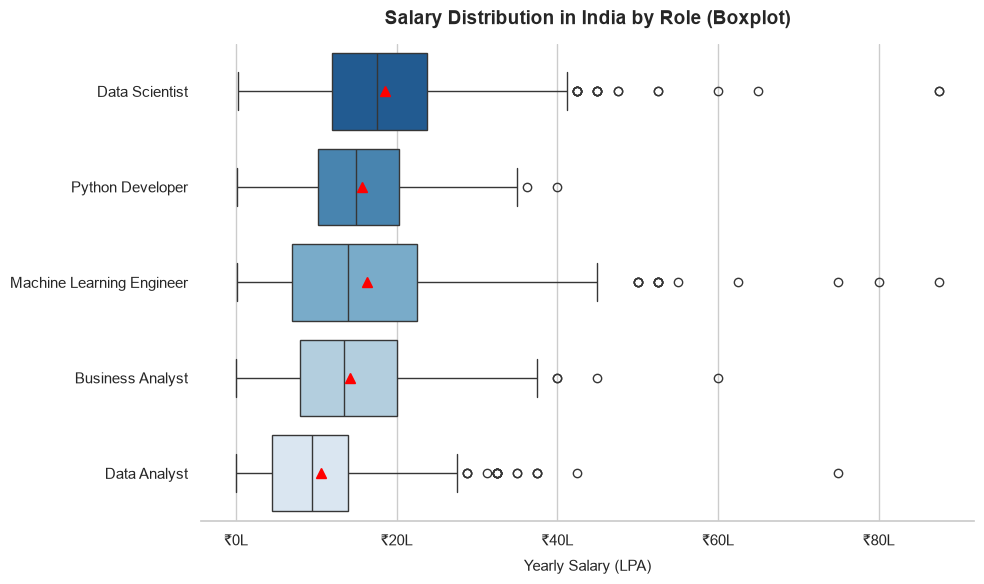

In [6]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

df_clean = df[df['salary_midpoint_lpa'] > 0].dropna(subset=['salary_midpoint_lpa']).copy()

top_roles = df_clean['role_category'].value_counts().head(5).index
df_clean = df_clean[df_clean['role_category'].isin(top_roles)]

order = df_clean.groupby('role_category')['salary_midpoint_lpa'].median().sort_values(ascending=False).index

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    data=df_clean,
    x='salary_midpoint_lpa',
    y='role_category',
    order=order,
    palette='Blues_r',
    showmeans=True,  
    meanprops={"marker": "^", "markerfacecolor": "red", "markeredgecolor": "red", "markersize": "7"},
    ax=ax
)

ax.set_title('Salary Distribution in India by Role (Boxplot)', fontsize=14, weight='bold', pad=14)
ax.set_xlabel('Yearly Salary (LPA)', fontsize=11, labelpad=8)
ax.set_ylabel('', fontsize=11)

ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda y, pos: f'₹{int(y)}L'))

sns.despine(left=True, bottom=False)
plt.tight_layout()
plt.show()

Investigate Median Salary Vs Skill for Data Analysts

In [7]:
df_IND = df[(df['job_title'] == 'Data Analyst') & (df['scraped_city'])].copy()

df_IND = df_IND.dropna(subset=['salary_year_avg'])

C:\Users\Admin\AppData\Local\Temp\ipykernel_12608\3660153685.py:1: Pandas4Warning: 'and' operations between boolean dtype and str are deprecated and will raise in a future version. Explicitly cast the strings to a boolean dtype before operating instead.
  df_IND = df[(df['job_title'] == 'Data Analyst') & (df['scraped_city'])].copy()


In [8]:
df_IND = df_IND.explode('skills_required')

df_IND[['salary_year_avg', 'skills_required']].head(5)

,salary_year_avg,skills_required
657,6.5,Data Analytics
657,6.5,Power Bi
657,6.5,Statistics
657,6.5,Python
657,6.5,SQL


In [ ]:
df_IND_toppay = df_IND.groupby('skills_required')['salary_year_avg'].agg(['count', 'median'])
.sort_values(by='count', ascending=False)

df_IND_toppay = df_IND_toppay.head(10)

SyntaxError: invalid syntax (1156932880.py, line 2)

In [ ]:
df_IND_skills = df_IND.groupby('skills_required')['salary_year_avg'].agg(['count', 'median']).sort_values(by='count', ascending=False)

df_IND_skills = df_IND_skills.head(10)

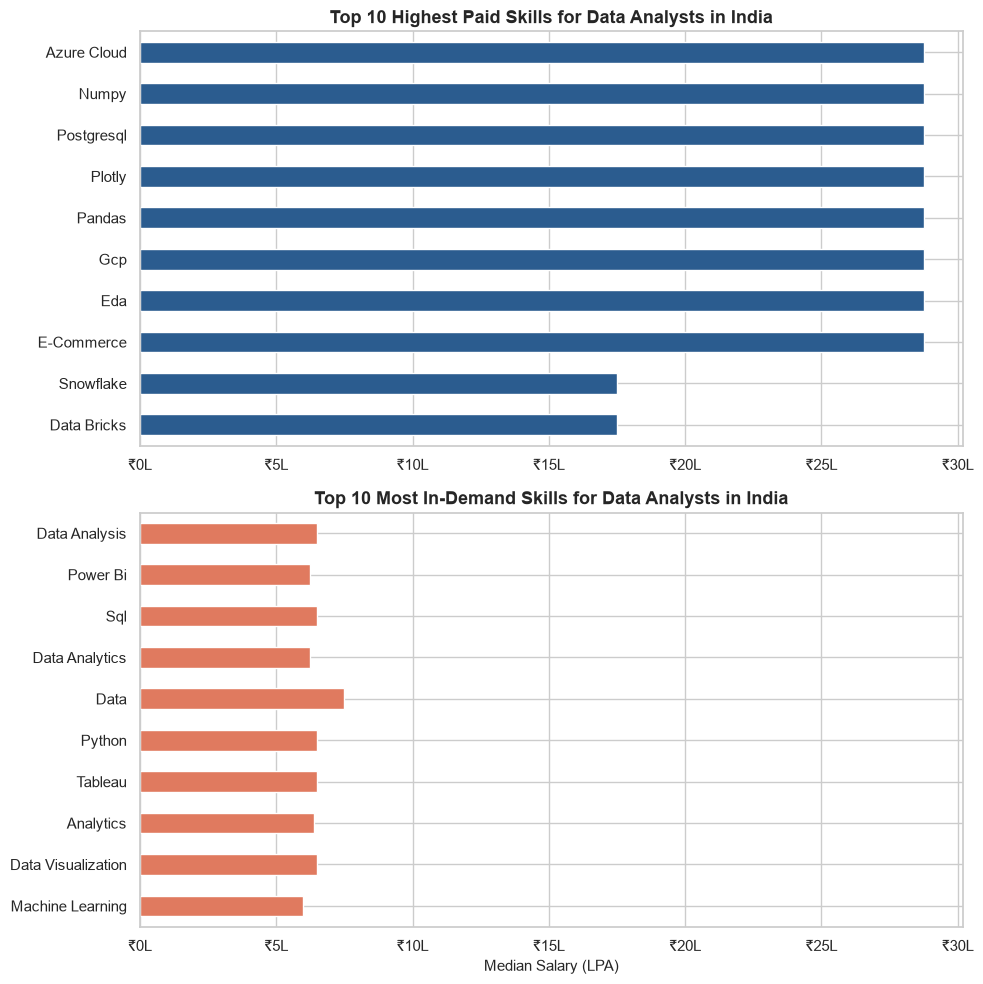

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

fig, ax = plt.subplots(2, 1, figsize=(10, 10))

df_IND_toppay[::-1].plot(kind='barh', y='median', ax=ax[0], legend=False, color='#2b5c8f')
ax[0].set_title('Top 10 Highest Paid Skills for Data Analysts in India', fontsize=13, weight='bold')
ax[0].set_xlabel('')
ax[0].set_ylabel('')
ax[0].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'₹{int(x)}L'))

df_IND_skills[::-1].plot(kind='barh', y='median', ax=ax[1], legend=False, color='#e07a5f')
ax[1].set_title('Top 10 Most In-Demand Skills for Data Analysts in India', fontsize=13, weight='bold')
ax[1].set_xlabel('Median Salary (LPA)', fontsize=11)
ax[1].set_ylabel('')

max_xlim = max(ax[0].get_xlim()[1], ax[1].get_xlim()[1])
ax[0].set_xlim(0, max_xlim)
ax[1].set_xlim(0, max_xlim)
ax[1].xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'₹{int(x)}L'))

fig.tight_layout()
plt.show()